# REACT tutorial: evaluate your own forecaster

REACT follows a probabilistic trajectory forecast through each detected change in a person's motion (a stop, a start, a turn) and reports four things per event:

- **anticipation**: the forecast never fell behind a climatological reference;
- **REACT**: frames until it was confidently ahead again;
- **censoring**: it never got there within the window;
- **relapse**: it got there, then fell behind again within 10 frames.

Every number is written $\mathrm{REACT}(h, d;\ I)$: lead $h$ in observations (frames), an optional target distance $d$ in metres, and an assumed information level $I$ in nats. This notebook takes a forecaster you write yourself through the whole workflow on real pedestrian data, and shows how to read the result.

It needs `pip install "reactmetric[viz,datasets]"` and about 10 minutes on a laptop.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import reactmetric as rm

print(rm.__version__)

0.2.0.dev0


## 1. Data

Eindhoven Centraal train-platform trajectories (Pouw et al., Zenodo 10.5281/zenodo.13784588, CC-BY-4.0), at 10 Hz in metres. The first call downloads one ten-day shard (about 860 MB) to `~/.cache/reactmetric`; `max_tracks` keeps this tutorial quick. With no download, `rm.datasets.load_eindhoven_sample()` gives a bundled 40-track excerpt, which is enough to run the code but too small for conclusions.

REACT needs **long, continuous tracks** (events need at least 25 frames before the next one) and a forecast at **every frame**, not one per scenario.

In [2]:
data = rm.datasets.load_eindhoven(download=True, max_tracks=600, seed=0)  # 600 random usable tracks
lengths = np.array([data[t].T for t in data.ids])
print(f"{len(data)} tracks, dt = {data.dt:.2f} s, median length {np.median(lengths) / 10:.0f} s, "
      f"{lengths.sum() / 10 / 3600:.1f} hours")

calib, test = data.split(fraction=0.3, seed=0)   # calibration fits REACT itself; never test on it
print(f"{len(calib)} calibration / {len(test)} test tracks")

600 tracks, dt = 0.10 s, median length 20 s, 8.1 hours
180 calibration / 420 test tracks


## 2. Your forecaster

A forecaster is anything with `predict(traj) -> rm.Predictive`. A `Predictive` holds, for each **issue frame** $t$, Gaussian forecasts of the position at frames $t+1, \dots, t+H$:

- `issue_frames` (n,): the **last observed frame**. The forecast may use observations up to and including it, never after.
- `means` (n, H, 2) and `covs` (n, H, 2, 2): column $h-1$ is lead $h$, which targets frame issue $+\ h$.

Here is a deliberately simple model: extrapolate the velocity of the last half second, with an isotropic spread that grows with lead.

In [3]:
class LinearExtrapolation:
    """Velocity from the last `history` frames; spread sigma0 + growth * (lead in seconds)."""

    def __init__(self, history=5, horizon=15, sigma0=0.03, growth=0.25):
        self.history, self.horizon, self.sigma0, self.growth = history, horizon, sigma0, growth

    def predict(self, traj):
        pos, dt, H = traj.positions, traj.dt, self.horizon
        issue = np.arange(self.history, len(pos) - 1)            # last observed frames
        if len(issue) == 0:
            return None
        v = (pos[issue] - pos[issue - self.history]) / (self.history * dt)
        leads = np.arange(1, H + 1) * dt                          # seconds ahead
        means = pos[issue][:, None, :] + leads[None, :, None] * v[:, None, :]
        sd = self.sigma0 + self.growth * leads
        covs = (sd**2)[None, :, None, None] * np.eye(2)
        return rm.Predictive(issue, means, np.broadcast_to(covs, (len(issue), H, 2, 2)).copy())


mine = LinearExtrapolation()
p = mine.predict(test[test.ids[0]])
target, mu, S = p.at_lead(10)
print(f"{len(p)} issue frames; lead 10 of the first forecast targets frame {target[0]} "
      f"(issued at {p.issue_frames[0]})")

37 issue frames; lead 10 of the first forecast targets frame 15 (issued at 5)


**Parallel runs and notebooks.** `evaluate(..., n_jobs=8)` scores tracks in worker processes. Classes defined in a notebook cannot be sent to those workers, so either keep `n_jobs=1` for notebook-defined models, or do what this tutorial does: compute the forecasts once into a dict `{track id: Predictive}`, which works with any `n_jobs`. In a script, put the run under `if __name__ == "__main__":`.

In [4]:
my_forecasts = {t: mine.predict(test[t]) for t in test.ids}
my_calib_forecasts = {t: mine.predict(calib[t]) for t in calib.ids}

## 3. Choose the events

REACT measures recovery from changes in motion, so *which* changes count is as much a part of the result as the forecasts. The default detector (`rm.events.BayesianChangepoints()`, the paper's) finds changepoints in each track's smoothed speed, turn rate and velocity, then types them from the motion before and after: `stop`, `start`, `speed_change` (at least 0.2 m/s), `turn` (at least 25°), and `both`.

Look at what it finds before you score anything. A detector that fires on noise inflates anticipation (there was nothing to anticipate); one that misses real changes leaves them inside other events' windows, where they show up as relapses.


In [5]:
det = rm.events.BayesianChangepoints()
found = det.detect_set(test)
types = pd.Series([e.event_type for evs in found.values() for e in evs])
print(f"{len(types)} events on {len(test)} test tracks "
      f"({len(types) / (sum(test[t].T for t in test.ids) * test.dt / 60):.1f} per minute)")
types.value_counts()


1073 events on 420 test tracks (2.9 per minute)


speed_change    632
both            156
start           102
stop             93
turn             72
turn_change      18
Name: count, dtype: int64

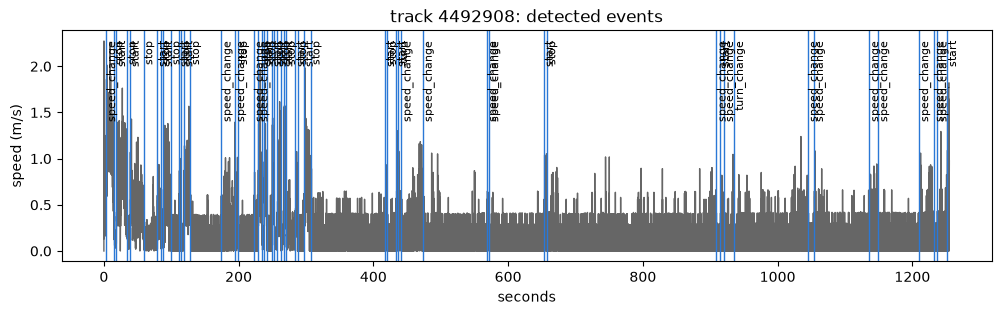

In [6]:
# one track with its events: a change should look like a change
tid = max(found, key=lambda t: len(found[t]))
pos = test[tid].positions
speed = np.r_[0, np.hypot(*np.diff(pos, axis=0).T)] / test.dt
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(np.arange(len(speed)) * test.dt, speed, lw=1, color="0.4")
for e in found[tid]:
    ax.axvline(e.t0 * test.dt, color="#2a78d6", lw=1)
    ax.text(e.t0 * test.dt + 0.3, speed.max(), e.event_type, fontsize=8, va="top", rotation=90)
ax.set(xlabel="seconds", ylabel="speed (m/s)", title=f"track {tid}: detected events")
plt.show()


**Measuring some events only.** Two ways, with different meanings:

- *Filter the result* (`result.subset(event_type="stop")`, or `result.table(by="event_type")`): every change is still detected and still ends the window of the change before it. Use this to compare models on, say, stops.
- *Select at scoring time* (`rm.ReactScorer.fit(calib, events=rm.events.select(det, types=("stop", "start")))`): only the chosen events exist, so windows run until the next chosen event. Use this when the other changes are not changes in your setting.

**Your own events.** With labelled manoeuvres, pass `rm.events.from_times({track_id: [frames, ...]})` as `events=`, for the calibration tracks too.

**Sensitivity.** The detector's hazard sets how readily it calls a change. The paper checks its conclusions across hazards (section 4.7); compare how many events a looser and a stricter setting find here, and rerun the evaluation with both if the counts differ much.


In [7]:
for hazard in (3e-4, 9e-4, 3e-3):
    d = rm.events.BayesianChangepoints(hazard=hazard)
    n = sum(len(d.detect(test[t])) for t in test.ids)
    print(f"hazard {hazard:.0e}: {n} events")


hazard 3e-04: 1009 events


hazard 9e-04: 1073 events


hazard 3e-03: 1125 events


## 4. Fit REACT on the calibration tracks

`ReactScorer.fit` fits everything REACT shares across models:

- the **climatology**: where a person is likely to be $h$ frames ahead given only their last step;
- the **measurement-noise floor** $\sigma$, from stationary frames;
- the **truth model's** correlation structure at each lead and information level;
- lookup tables for the exact tests.

Passing models here also reports their **demonstrated information**: the mean realized gain over climatology on calm stretches. It is a lower bound on how much information the trajectories carry.

The paper reports 3, 4.2 and 6 nats with 4.2 as the headline. Leads 5 and 10 keep this quick (the paper also uses 1 and 15).

In [8]:
cv = rm.baselines.ConstantVelocity.fit(calib)        # maximum-likelihood noise on calibration
scorer = rm.ReactScorer.fit(
    calib, info=(3.0, 4.2, 6.0), leads=(5, 10), distortions=(0.1, 0.3),
    forecasts={"Mine": my_calib_forecasts, "CV": cv}, n_jobs=os.cpu_count(),
)
print("noise floor:", f"{scorer.noise_floor['sigma_cm']:.2f} cm")
for lead in scorer.leads:
    print(f"lead {lead}: demonstrated information (nats/frame)",
          {m: round(v, 2) for m, v in scorer.diagnostics[lead]["calm_mean_score"].items()})

noise floor: 1.00 cm
lead 5: demonstrated information (nats/frame) {'Mine': 0.05, 'CV': 0.4}
lead 10: demonstrated information (nats/frame) {'Mine': 0.11, 'CV': 0.23}


## 5. Evaluate against baselines

Constant velocity (fitted above), CTRV and IMM (default noise), and **Oracle B**, which is always included: the best forecast the assumptions allow, so its REACT is the floor.

Models are compared on the events they all cover (`event_set="shared"`, the default), and `result.coverage` says how many that is per lead.


In [9]:
models = {"Mine": my_forecasts, "CV": cv, "CTRV": rm.baselines.CTRV(), "IMM": rm.baselines.IMM()}
result = scorer.evaluate(models, test, n_jobs=os.cpu_count())
result


/var/folders/sp/snm4gg7x1p1bj9dkb391tk040000gn/T/ipykernel_86378/4056975505.py:2: RuntimeWarning: lead 5: 89 of 1073 events lack a forecast window from every model and are left out so all models are compared on the same 984 events (events missing per model: {'CV': 89, 'CTRV': 89, 'IMM': 89}); pass event_set='all' to keep them
  result = scorer.evaluate(models, test, n_jobs=os.cpu_count())
/var/folders/sp/snm4gg7x1p1bj9dkb391tk040000gn/T/ipykernel_86378/4056975505.py:2: RuntimeWarning: lead 10: 45 of 1073 events lack a forecast window from every model and are left out so all models are compared on the same 1028 events (events missing per model: {'CV': 45, 'CTRV': 45, 'IMM': 45}); pass event_set='all' to keep them
  result = scorer.evaluate(models, test, n_jobs=os.cpu_count())


ReactResult(1028 events, models=['Mine', 'CV', 'CTRV', 'IMM', 'oracle_B'], leads=[5, 10], info=[3.0, 4.2, 6.0], distortions=[inf, 0.1 m, 0.3 m])

## 6. Read the profile

One row per model at $\mathrm{REACT}(10, \infty;\ I)$. `table()` picks the information level by the paper's rule (section 7 below) and says why in `attrs`:

- `anticipated`: share of events where the forecast never fell confidently behind.
- `recovered` / `censored`: share that fell behind and then recovered / never recovered within the window (the three shares sum to 1).
- `median_react`: median frames to recovery, given onset (Kaplan–Meier).
- `rmst`: restricted mean frames to recovery over all events, anticipated ones at 0. The most stable single number for comparisons.
- `relapsed`: share of recoveries that fell behind again within 10 frames.

`rm.results.GLOSSARY` defines every column of `table(columns="all")`.


In [10]:
tb = result.table(lead=10)
print(tb.attrs["info_reason"])
tb.round(2)


the paper's rule: the lowest level at which Oracle B recovers on >= 95% of events at every lead, at d = 0.1 m


,lead,info,distortion,model,events,anticipated,recovered,censored,median_react,rmst,relapsed
0,10,4.2,None,Mine,1028,0.16,0.71,0.12,11.0,27.29,0.32
1,10,4.2,None,CV,1028,0.16,0.72,0.12,11.0,26.83,0.33
2,10,4.2,None,CTRV,1028,0.10,0.80,0.10,14.0,26.70,0.51
3,10,4.2,None,IMM,1028,0.13,0.79,0.08,12.0,23.63,0.46
4,10,4.2,None,oracle_B,1028,0.00,1.00,0.00,1.0,1.07,0.00


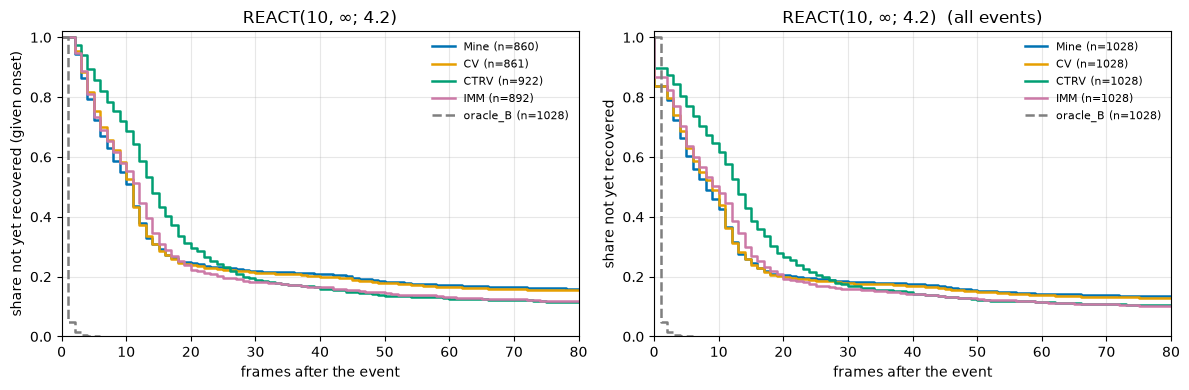

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rm.viz.km_curves(result, lead=10, given_onset=True, max_frames=80, ax=axes[0])
rm.viz.km_curves(result, lead=10, given_onset=False, max_frames=80, ax=axes[1])
axes[1].set_title(axes[1].get_title() + "  (all events)")
plt.show()

Read the left panel as: of the events where a model fell behind, what share has not yet recovered $\tau$ frames later. A curve that drops early recovers quickly; a curve that flattens high leaves events unrecovered. The right panel counts anticipated events as recovered at frame 0.

**Is the difference real?** Events on one track are correlated, so intervals resample whole tracks. `compare` is paired: both models are evaluated on the same resampled events. For `rmst`, a negative difference means the first model recovers sooner.


In [12]:
print(result.ci("rmst", model="Mine", lead=10))
print(result.compare("Mine", "CV", "rmst", lead=10))
result.table(lead=10, ci=True, n_boot=500)[["model", "rmst", "rmst_low", "rmst_high"]].round(1)


{'estimate': 27.28784553908341, 'low': 22.552681186920076, 'high': 32.0098227239908, 'events': 1028, 'tracks': 268}


{'a': 27.28784553908341, 'b': 26.830186787159413, 'difference': 0.4576587519239972, 'low': -0.5456854577349404, 'high': 1.4388846939696194, 'share_a_lower': 0.1835, 'events': 1028, 'tracks': 268}


,model,rmst,rmst_low,rmst_high
0,Mine,27.3,22.4,32.0
1,CV,26.8,22.5,31.4
2,CTRV,26.7,23.0,30.7
3,IMM,23.6,19.8,27.6
4,oracle_B,1.1,1.0,1.1


## 7. Choose the target and the information level

**Target distance $d$.** Beating climatology is a relative advantage. With $d = 0.1$ m, recovery also requires the forecast to be sharp enough to localize the person within 10 cm RMS. Oracle B's censoring shows whether a target is reachable at all.

In [13]:
result.table(lead=10, distortion=0.1).round(2)


,lead,info,distortion,model,events,anticipated,recovered,censored,median_react,rmst,relapsed
0,10,4.2,0.1,Mine,1028,0.16,0.52,0.31,35.0,57.13,0.20
1,10,4.2,0.1,CV,1028,0.16,0.54,0.29,33.0,54.22,0.20
2,10,4.2,0.1,CTRV,1028,0.10,0.61,0.29,35.0,56.06,0.41
3,10,4.2,0.1,IMM,1028,0.13,0.60,0.27,32.0,52.61,0.35
4,10,4.2,0.1,oracle_B,1028,0.00,0.95,0.05,2.0,10.52,0.00


**Information level $I$.** An assumption about how much of the next position is knowable beyond climatology. Raising it makes each frame more decisive and shortens REACT. Report results with their level, and check that model orderings hold across levels.
`table()` picks the level by the paper's rule: the lowest level at which Oracle B recovers on at least 95% of events at every lead, judged at the smallest finite target. Ask for any level with `info=`.


In [14]:
pd.concat([result.table(lead=10, info=info).set_index("model")["rmst"].rename(f"I = {info}")
           for info in (3.0, 4.2, 6.0)], axis=1).round(1)


,I = 3.0,I = 4.2,I = 6.0
model,,,
Mine,29.4,27.3,25.9
CV,28.9,26.8,25.6
CTRV,32.5,26.7,22.9
IMM,26.7,23.6,20.8
oracle_B,1.3,1.1,1.0


In [15]:
level, reason = result.headline_info()
print(level, "nats:", reason)
pd.DataFrame(result.info_level()[1]).round(3)      # Oracle B's recovered share, level x lead


4.2 nats: the paper's rule: the lowest level at which Oracle B recovers on >= 95% of events at every lead, at d = 0.1 m


,3.0,4.2,6.0
5,0.934,0.965,0.994
10,0.922,0.954,0.978


## 8. Drill into events

Every record is one (lead, level, target, model, event). Break the table down by event type, or work with the records directly.


In [16]:
result.table(lead=10, by="event_type")[["model", "event_type", "events", "anticipated",
                                         "censored", "rmst"]].round(2)


,model,event_type,events,anticipated,censored,rmst
0,Mine,both,148,0.14,0.00,6.73
1,Mine,speed_change,603,0.15,0.13,29.81
2,Mine,start,97,0.47,0.00,3.81
3,Mine,stop,93,0.03,0.42,73.69
4,Mine,turn,70,0.09,0.00,7.16
5,Mine,turn_change,17,0.06,0.47,80.90
6,CV,both,148,0.14,0.00,7.20
7,CV,speed_change,603,0.16,0.13,29.80
8,CV,start,97,0.44,0.00,5.26
9,CV,stop,93,0.02,0.37,66.10


## 9. A multimodal version of your model

If your model can say "keeps walking, or stops", give it as a mixture. REACT scores the mixture itself, so a correct second mode is rewarded rather than blurred into one wide Gaussian.

In [17]:
class StopOrGo(LinearExtrapolation):
    """70%: keep going (the linear model); 30%: stop where you are."""

    def predict(self, traj):
        p = super().predict(traj)
        if p is None:
            return None
        n, H = p.means.shape[:2]
        stay = np.repeat(traj.positions[p.issue_frames][:, None, :], H, axis=1)
        means = np.stack([p.means, stay], axis=2)                          # (n, H, 2 modes, 2)
        covs = np.stack([p.covs, np.broadcast_to(0.05**2 * np.eye(2), p.covs.shape)], axis=2)
        return rm.MixturePredictive(p.issue_frames, np.tile([0.7, 0.3], (n, 1)), means, covs)


both = scorer.evaluate({"Mine": my_forecasts,
                        "StopOrGo": {t: StopOrGo().predict(test[t]) for t in test.ids}},
                       test, n_jobs=os.cpu_count())
both.table(lead=10, info=4.2).round(2)

,lead,info,distortion,model,events,anticipated,recovered,censored,median_react,rmst,relapsed
0,10,4.2,None,Mine,1073,0.16,0.72,0.12,10.0,26.48,0.32
1,10,4.2,None,StopOrGo,1073,0.14,0.77,0.08,9.0,21.36,0.39
2,10,4.2,None,oracle_B,1073,0.00,1.00,0.00,1.0,1.07,0.00


## 10. Save, with the assumptions

`to_json` writes the settings every number depends on (leads, levels, targets, windows, noise floor), the summary and the per-event records; `ReactResult.load` reads it back with everything working as before. `scorer.save` keeps the fit itself, to score more models later.


In [18]:
os.makedirs("react_tutorial", exist_ok=True)
result.to_json("react_tutorial/result.json")
again = rm.ReactResult.load("react_tutorial/result.json")
again.table(lead=10).equals(result.table(lead=10))


True

## Notes

- Leads and windows are counted in observations; the defaults are the paper's choices for 10 Hz data. `docs/concepts.md` shows how to set them for another frame rate.
- REACT is a profile, not a leaderboard number: anticipation, recovery time, completeness and relapse can favour different models.
- Which events you measure shapes every number; section 3 and `docs/events.md`.
- Method and defaults: the paper (Breseman and Woollard, *REACT: Measuring Regime Adaptation in Trajectories*, TGF 2026) and `docs/concepts.md`.
